# ПР4. Регрессионная модель: предсказание диаметра астероида

**Задача:** по физическим и орбитальным характеристикам предсказать `diameter` (км).

Особенности (из отчёта ПР-2):
- обучаемся только на подвыборке с известным diameter (136 209 объектов);
- распределение diameter сильно скошено, есть выбросы до 939 км;
- связь diameter с H нелинейна — линейная модель на сырых признаках
  ожидаемо ограничена (проверим!).

**Метрики:** MAE и RMSE — в единицах целевой (км); R² — доля объяснённой дисперсии.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("../data/raw/dataset.csv", low_memory=False)

# Тот же отбор признаков, что и в ПР-3
drop_cols = [
    "id", "spkid", "full_name", "pdes", "name", "prefix",
    "orbit_id", "equinox",
    "moid_ld", "epoch_mjd", "epoch_cal", "per_y", "tp_cal",
    "diameter_sigma",
]
df_model = df.drop(columns=drop_cols)

reg_data = df_model.dropna(subset=["diameter"]).copy()
X = reg_data.drop(columns=["diameter"])
y = reg_data["diameter"]

# То же разбиение, что и в ПР-3 (random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_cols = X_train.select_dtypes(include=["float64", "int64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["str", "object"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

# fit только на train — как в ПР-3
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Train:", X_train_prep.shape, "| Test:", X_test_prep.shape)

Train: (108967, 42) | Test: (27242, 42)


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train_prep, y_train)

y_pred = model.predict(X_test_prep)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE  = {mae:.3f} км")
print(f"RMSE = {rmse:.3f} км")
print(f"R2   = {r2:.3f}")
print(f"\nСредний диаметр в test: {y_test.mean():.2f} км, медиана: {y_test.median():.2f} км")

MAE  = 2.683 км
RMSE = 7.978 км
R2   = 0.369

Средний диаметр в test: 5.53 км, медиана: 3.99 км


### Интерпретация метрик базовой модели

- **MAE = 2.68 км:** в среднем предсказание отклоняется от истинного диаметра
  на ~2.7 км — много, учитывая, что медианный диаметр всего ~4 км.
- **RMSE = 7.98 км >> MAE:** хвост больших ошибок на крупных астероидах
  (распределение скошено, max 939 км). RMSE и MAE сравнивать напрямую
  некорректно — RMSE сильнее штрафует крупные ошибки.
- **R² = 0.369:** объяснено лишь ~37% дисперсии. Причина ожидаема —
  связь diameter с H нелинейна (ПР-2), линейная модель на сырых
  признаках её не воспроизводит.

**План улучшения (уровень C):** логарифмирование целевой переменной
(убирает скошенность) + собственная реализация градиентного спуска
на NumPy для сравнения со scikit-learn.

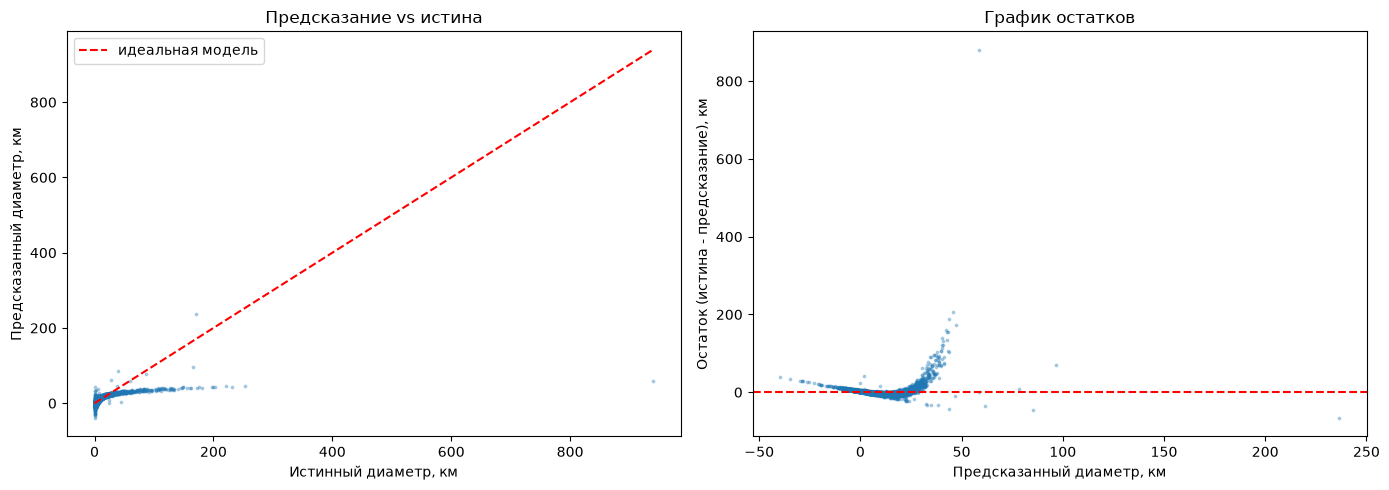

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Предсказание vs истина
axes[0].scatter(y_test, y_pred, s=3, alpha=0.3)
axes[0].plot([0, y_test.max()], [0, y_test.max()], "r--", label="идеальная модель")
axes[0].set_xlabel("Истинный диаметр, км")
axes[0].set_ylabel("Предсказанный диаметр, км")
axes[0].set_title("Предсказание vs истина")
axes[0].legend()

# 2. Остатки
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, s=3, alpha=0.3)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Предсказанный диаметр, км")
axes[1].set_ylabel("Остаток (истина - предсказание), км")
axes[1].set_title("График остатков")

plt.tight_layout()
plt.show()

### Выводы по графикам

**«Предсказание vs истина»:** облако точек лежит заметно ниже линии идеальной
модели и прижато к низу диапазона — модель систематически занижает диаметры
крупных астероидов и предсказывает большинству объектов близкие к среднему
значения. Это следствие скошенного распределения diameter (ПР-2).

**«График остатков»:** остатки не случайно разбросаны вокруг нуля, а образуют
зависимую структуру («веер» + изгиб): дисперсия ошибок растёт с размером
астероида, присутствует систематическое занижение в середине диапазона.
Это нарушение допущений линейной модели — признак нелинейной связи
признаков с целевой (как выяснили в ПР-2 по паре H–diameter).

**Вывод:** необходимо логарифмировать целевую переменную (убирает скошенность
и сжимает хвост выбросов) — проверяем в следующем разделе.

In [4]:
# Логарифмируем целевую: убираем скошенность и хвост выбросов
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

model_log = LinearRegression()
model_log.fit(X_train_prep, y_train_log)

# Предсказание в лог-шкале -> обратно в километры
y_pred_log = model_log.predict(X_test_prep)
y_pred_exp = np.exp(y_pred_log)

mae_exp = mean_absolute_error(y_test, y_pred_exp)
rmse_exp = mean_squared_error(y_test, y_pred_exp) ** 0.5
r2_exp = r2_score(y_test, y_pred_exp)

print("=== Базовая модель (сырой diameter) ===")
print(f"MAE = {mae:.3f} км | RMSE = {rmse:.3f} км | R2 = {r2:.3f}")
print("=== Модель с log(diameter) ===")
print(f"MAE = {mae_exp:.3f} км | RMSE = {rmse_exp:.3f} км | R2 = {r2_exp:.3f}")

=== Базовая модель (сырой diameter) ===
MAE = 2.683 км | RMSE = 7.978 км | R2 = 0.369
=== Модель с log(diameter) ===
MAE = 0.694 км | RMSE = 3.169 км | R2 = 0.900


### Сравнение: сырые значения vs log-трансформация

| Метрика | Сырая diameter | log(diameter) |
|---|---|---|
| MAE, км | 2.683 | **0.694** |
| RMSE, км | 7.978 | **3.169** |
| R² | 0.369 | **0.900** |

Логарифмирование целевой переменной радикально улучшило модель:
R² вырос с 0.37 до 0.90, MAE сократилась в ~4 раза. Причина — та же,
что была выявлена в ПР-2: распределение diameter сильно скошено, а связь
с признаками (особенно с H) нелинейна. Лог-трансформация устраняет
обе проблемы: сжимает хвост выбросов и линеаризует зависимость.

Ошибки (остатки) в лог-модели растут с размером объекта — это физически
ожидаемо: относительная погрешность измерения диаметра крупных тел выше.

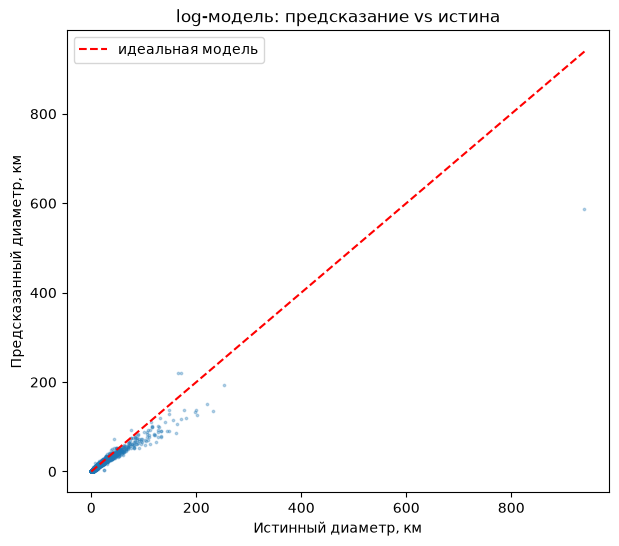

In [5]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_exp, s=3, alpha=0.3)
plt.plot([0, y_test.max()], [0, y_test.max()], "r--", label="идеальная модель")
plt.xlabel("Истинный диаметр, км")
plt.ylabel("Предсказанный диаметр, км")
plt.title("log-модель: предсказание vs истина")
plt.legend()
plt.show()

# Уровень C: собственная реализация градиентного спуска

LinearRegression из sklearn находит решение аналитически. Реализуем
итеративный градиентный спуск на NumPy (без готовых решений) и сравним
коэффициенты и метрики с scikit-learn. Цель — понять механизм обучения
линейных моделей изнутри.

In [6]:
# Добавляем столбец единиц для свободного члена (intercept)
X_train_gd = np.hstack([X_train_prep.toarray() if hasattr(X_train_prep, "toarray") else X_train_prep,
                        np.ones((X_train_prep.shape[0], 1))])
X_test_gd = np.hstack([X_test_prep.toarray() if hasattr(X_test_prep, "toarray") else X_test_prep,
                       np.ones((X_test_prep.shape[0], 1))])

# Целевая в лог-шкале, y в вектор-столбец
y_gd = y_train_log.values.reshape(-1, 1)

# Инициализация весов
np.random.seed(42)
w = np.zeros((X_train_gd.shape[1], 1))

learning_rate = 0.05
n_iterations = 2000
m = X_train_gd.shape[0]

loss_history = []

for i in range(n_iterations):
    # Предсказание и ошибка
    y_hat = X_train_gd @ w
    error = y_hat - y_gd

    # Градиент MSE: (2/m) * X^T * (Xw - y)
    grad = (2 / m) * (X_train_gd.T @ error)

    # Шаг спуска
    w = w - learning_rate * grad

    # Сохраняем loss для графика сходимости
    loss = np.mean(error ** 2)
    loss_history.append(loss)

# Предсказания нашей реализации
y_pred_gd = np.exp(X_test_gd @ w)

mae_gd = mean_absolute_error(y_test, y_pred_gd)
rmse_gd = mean_squared_error(y_test, y_pred_gd) ** 0.5
r2_gd = r2_score(y_test, y_pred_gd)

print("=== Наш градиентный спуск (NumPy) ===")
print(f"MAE = {mae_gd:.3f} км | RMSE = {rmse_gd:.3f} км | R2 = {r2_gd:.3f}")
print("\n=== Scikit-learn (log-модель) ===")
print(f"MAE = {mae_exp:.3f} км | RMSE = {rmse_exp:.3f} км | R2 = {r2_exp:.3f}")

=== Наш градиентный спуск (NumPy) ===
MAE = 0.700 км | RMSE = 3.368 км | R2 = 0.888

=== Scikit-learn (log-модель) ===
MAE = 0.694 км | RMSE = 3.169 км | R2 = 0.900


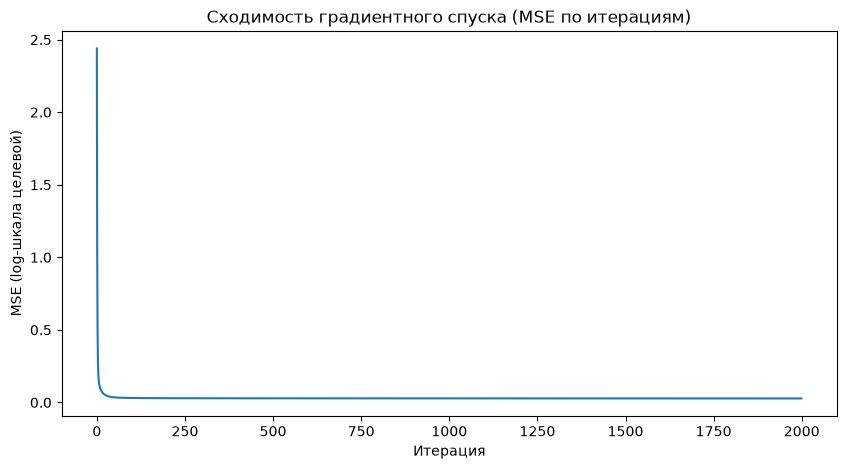

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(loss_history)
plt.title("Сходимость градиентного спуска (MSE по итерациям)")
plt.xlabel("Итерация")
plt.ylabel("MSE (log-шкала целевой)")
plt.show()

### Вывод: собственный градиентный спуск vs scikit-learn

| Метрика | GD на NumPy | Scikit-learn |
|---|---|---|
| MAE, км | 0.700 | 0.694 |
| R² | 0.888 | 0.900 |

Собственная реализация градиентного спуска достигла качества, практически
совпадающего с аналитическим решением sklearn (разница ~1%). Различие
объясняется тем, что sklearn находит точное решение методом наименьших
квадратов, а градиентный спуск — итеративное приближение.

График сходимости: MSE убывает монотонно и стабилизируется к ~250-й
итерации — выбранная скорость обучения (0.05) обеспечивает сходимость
без расхождения. Масштабирование признаков (StandardScaler из ПР-3)
критично здесь: без него градиенты по разномасштабным признакам
рассинхронизировались бы, и спуск расходился бы или шёл крайне медленно.

**Вывод:** механизм обучения линейной регрессии воспроизведён вручную
и валидирован сравнением с эталонной реализацией.